## imports


In [5]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from  sklearn.preprocessing import MinMaxScaler

## yfinance install

In [6]:
%pip install -i http://mirrors.aliyun.com/pypi/simple --trusted-host mirrors.aliyun.com yfinance

Looking in indexes: http://mirrors.aliyun.com/pypi/simple
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import yfinance as yf

##  Data Acquisition and Preparation

In [8]:
#download the Google data
df = yf.download('GOOGL',
                 start='2019-01-01',
                 end='2024-12-31',
                 progress=False)
# show information
print("download is finish")
print(f"Shape: {df.shape}")
print(df.head())

download is finish
Shape: (1509, 5)
Price           Close       High        Low       Open    Volume
Ticker          GOOGL      GOOGL      GOOGL      GOOGL     GOOGL
Date                                                            
2019-01-02  52.270515  52.573330  50.813434  50.908591  31868000
2019-01-03  50.822845  52.844421  50.669209  52.071773  41960000
2019-01-04  53.429729  53.525382  51.387339  51.669833  46022000
2019-01-07  53.323174  53.659191  52.665008  53.573453  47446000
2019-01-08  53.791523  54.187014  52.948001  53.822744  35414000


In [9]:
#SOLVE MultiIndex 
df_clean = pd.DataFrame({
    'Close': df[('Close', 'GOOGL')],
    'High': df[('High', 'GOOGL')],
    'Low': df[('Low', 'GOOGL')],
    'Open': df[('Open', 'GOOGL')],
    'Volume': df[('Volume', 'GOOGL')]
}).round(3)

print(df_clean.head(10))
print("columns:", df_clean.columns.tolist())

             Close    High     Low    Open    Volume
Date                                                
2019-01-02  52.271  52.573  50.813  50.909  31868000
2019-01-03  50.823  52.844  50.669  52.072  41960000
2019-01-04  53.430  53.525  51.387  51.670  46022000
2019-01-07  53.323  53.659  52.665  53.573  47446000
2019-01-08  53.792  54.187  52.948  53.823  35414000
2019-01-09  53.607  54.102  53.246  53.921  26998000
2019-01-10  53.467  53.516  52.766  53.275  26598000
2019-01-11  52.756  53.197  52.357  53.025  30864000
2019-01-14  52.113  52.457  51.967  52.204  28490000
2019-01-15  53.848  53.935  52.259  52.436  37518000
columns: ['Close', 'High', 'Low', 'Open', 'Volume']


<Axes: xlabel='Date'>

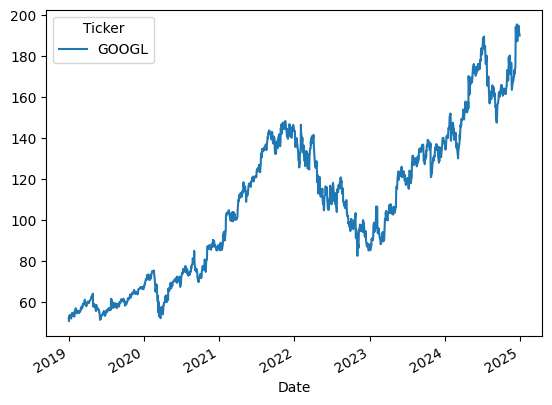

In [10]:
df.Close.plot()

In [11]:
df.Close.shape

(1509, 1)

In [12]:
df_clean[:"2020"].Close.values.reshape(-1, 1).shape

(505, 1)

In [13]:
df_clean["2021":].Close.values.shape

(1004,)

## Function

In [14]:
def ts_data(df, X_steps, y_steps):
    # separate train و test
    train_df = df[:"2020"].Close.values.reshape(-1, 1)
    test_df = df["2021":].Close.values.reshape(-1, 1)
    
    # Normalisation
    sc = MinMaxScaler(feature_range=(0, 1))
    train_df_scaled = sc.fit_transform(train_df)
    
    # creat X_train و y_train
    X_train = []
    y_train = []
    for i in range(X_steps, len(train_df_scaled) - y_steps + 1):
        X_train.append(train_df_scaled[i - X_steps:i, 0])
        y_train.append(train_df_scaled[i:i + y_steps, 0])
    
    X_train = np.array(X_train)
    y_train = np.array(y_train)
    
    # Reshape for RNN (add feature dimension)
    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    
    # Test data preparation
    X = df.Close.values
    X = X[len(X) - len(test_df) - X_steps:]
    X = X.reshape(-1, 1)
    X = sc.transform(X)
    
    # creat X_test و y_test
    X_test = []
    y_test = []
    for i in range(X_steps, len(test_df) + X_steps - y_steps + 1):
        X_test.append(X[i - X_steps:i, 0])
        y_test.append(X[i:i + y_steps, 0])
    
    X_test = np.array(X_test)
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
    y_test = np.array(y_test)
    
    return X_train, y_train, X_test, y_test, sc

In [15]:
df_clean[:"2020"].Close.values.reshape(-1, 1).shape

(505, 1)

In [16]:
X_steps = 10
y_steps = 3

# ساخت داده با df_clean
X_train, y_train, X_test, y_test, scaler = ts_data(df_clean, X_steps, y_steps)

print("data  :")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_test:  {y_test.shape}")

data  :
X_train: (493, 10, 1)
y_train: (493, 3)
X_test:  (1002, 10, 1)
y_test:  (1002, 3)


## model RNN

In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Dense,Dropout
## creat model
model=Sequential([  ## layer1
                   SimpleRNN(units=50, return_sequences=True, input_shape=(X_steps, 1)),
                   Dropout(0.2), 
                    ## layer 2
                   SimpleRNN(units=50, return_sequences=False),
                   Dropout(0.2),
                    ## last layer
                    Dense(y_steps)
                 ])
    

C:\Users\Ayda\tf_env_310\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## model compile

In [18]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
 ## show model summery
model.summary()

print("model is done")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 10, 50)              │           2,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 10, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_1 (SimpleRNN)             │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │             153 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,803 (30.48 KB)

 Trainable params: 7,803 (30.48 KB)

 Non-trainable params: 0 (0.00 B)

model is done


## model fit

In [19]:
 history = model.fit(
                X_train, y_train,
                validation_data=(X_test, y_test),
                epochs=15,
                batch_size=32,
                verbose=1
            )

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.1683 - mae: 0.2979 - val_loss: 2.1804 - val_mae: 1.2777
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0589 - mae: 0.1840 - val_loss: 1.7003 - val_mae: 1.0901
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0386 - mae: 0.1485 - val_loss: 1.4827 - val_mae: 1.0074
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0315 - mae: 0.1339 - val_loss: 1.3819 - val_mae: 0.9657
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0266 - mae: 0.1209 - val_loss: 1.1971 - val_mae: 0.8874
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0245 - mae: 0.1123 - val_loss: 1.1430 - val_mae: 0.8691
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0216 - mae: 0.1086 - val_loss: 1.0017 - val_mae: 0.7978
Epoch 8/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0210 - mae: 0.1046 - val_loss: 0.9139 - val_mae: 0.7538
Epoch 9/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0186 - mae

## Model Evaluation

In [20]:
## final result
train_loss = history.history['loss'][-1]
val_loss = history.history['val_loss'][-1]
train_mae = history.history['mae'][-1]
val_mae = history.history['val_mae'][-1]

print("final result:")
print(f"Loss (Train):        {train_loss:.5f}")
print(f"Loss (Validation):   {val_loss:.5f}")
print(f"MAE (Train):         {train_mae:.5f}")
print(f"MAE (Validation):    {val_mae:.5f}")


final result:
Loss (Train):        0.01341
Loss (Validation):   0.67240
MAE (Train):         0.08637
MAE (Validation):    0.65732


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Predictions shape: (1002, 3)


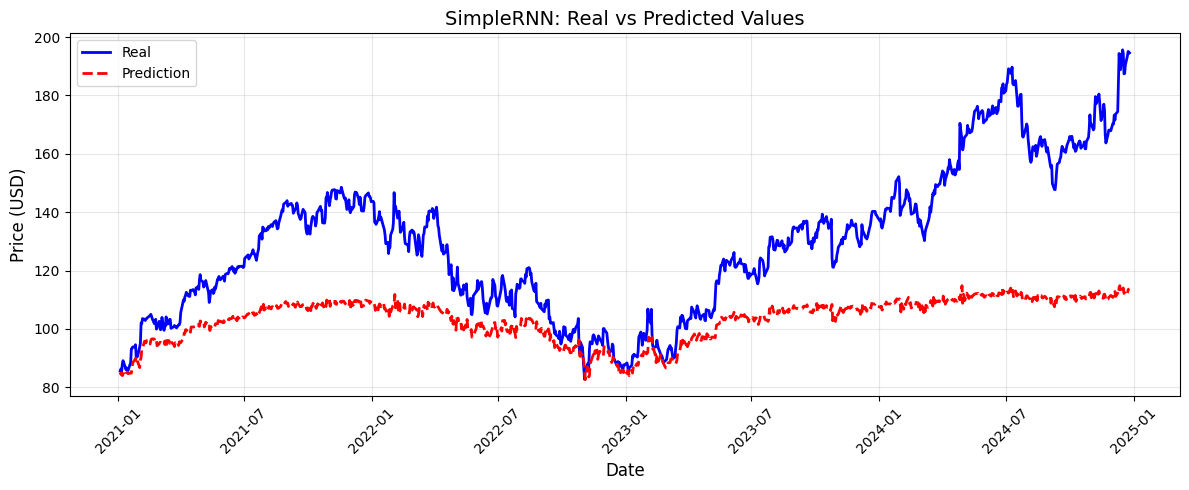

In [21]:
# Predict on test data
simple_rnn_pred = model.predict(X_test)
print("Predictions shape:", simple_rnn_pred.shape)

# Define prediction plot function
def prediction_plot(predictions):
    fig, ax = plt.subplots(figsize=(12, 5))
    
    # Real values (first day of future predictions)
    ax.plot(df_clean["2021":].index[:len(y_test)],
            scaler.inverse_transform(y_test[:, 0].reshape(-1, 1)), 
            label="Real", color='blue', linewidth=2)
    
    # Predicted values (first day of future predictions)
    ax.plot(df_clean["2021":].index[:len(y_test)],
            scaler.inverse_transform(predictions[:, 0].reshape(-1, 1)), 
            label="Prediction", color='red', linestyle='--', linewidth=2)
    
    ax.set_title('SimpleRNN: Real vs Predicted Values', fontsize=14)
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel('Price (USD)', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Call the function
prediction_plot(simple_rnn_pred)

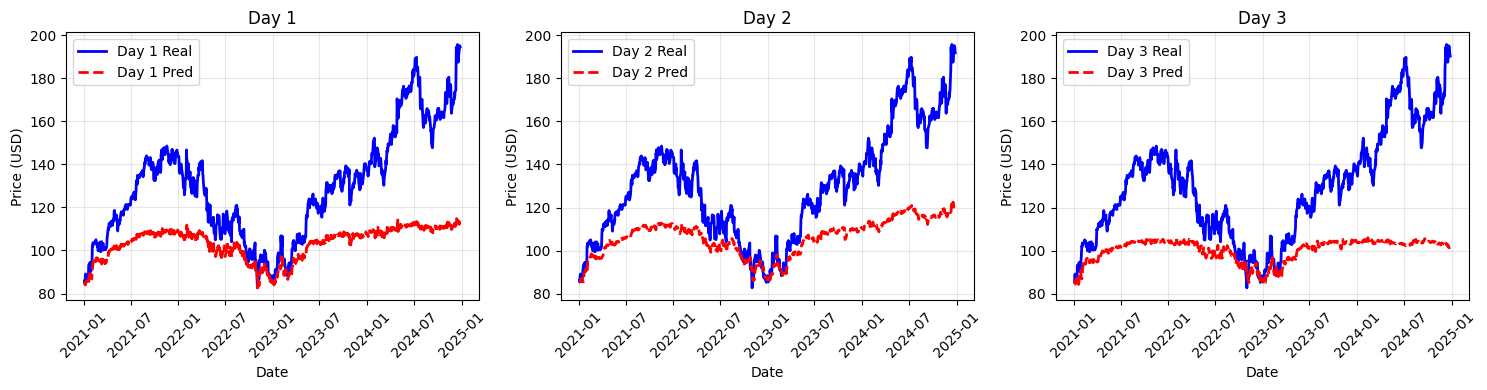

In [22]:
# Plot all 3 future days separately
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(y_test[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Real', color='blue', linewidth=2)
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(simple_rnn_pred[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Pred', color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'Day {i+1}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [23]:
from tensorflow.keras.layers import LSTM

## LSTM Model

In [24]:
lstm_model = Sequential([
    LSTM(units=50, return_sequences=True, input_shape=(X_steps, 1)),
    Dropout(0.2),
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(y_steps)
])


C:\Users\Ayda\tf_env_310\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Model Compile 

In [25]:
lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 10, 50)              │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 10, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             153 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 30,753 (120.13 KB)

 Trainable params: 30,753 (120.13 KB)

 Non-trainable params: 0 (0.00 B)

## Model Fit

In [26]:
lstm_history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.1001 - mae: 0.2356 - val_loss: 0.3864 - val_mae: 0.4767
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0213 - mae: 0.1158 - val_loss: 0.7652 - val_mae: 0.7661
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0113 - mae: 0.0800 - val_loss: 0.3169 - val_mae: 0.4326
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0090 - mae: 0.0700 - val_loss: 0.2475 - val_mae: 0.3703
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0078 - mae: 0.0643 - val_loss: 0.1880 - val_mae: 0.3114
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0079 - mae: 0.0648 - val_loss: 0.1688 - val_mae: 0.2880
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0077 - mae: 0.0640 - val_loss: 0.1811 - val_mae: 0.3053
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0077 - mae: 0.0630 - val_loss: 0.1879 - val_mae: 0.3162
Epoch 9/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0078 - m

## Model Evaluation

In [27]:
lstm_train_mae = lstm_history.history['mae'][-1]
lstm_val_mae = lstm_history.history['val_mae'][-1]

print(f"\nLSTM Results:")
print(f"Train MAE: {lstm_train_mae:.5f}")
print(f"Validation MAE: {lstm_val_mae:.5f}")



LSTM Results:
Train MAE: 0.04974
Validation MAE: 0.29048


## prediction

In [28]:
lstm_pred = lstm_model.predict(X_test)
print(f"Predictions shape: {lstm_pred.shape}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Predictions shape: (1002, 3)


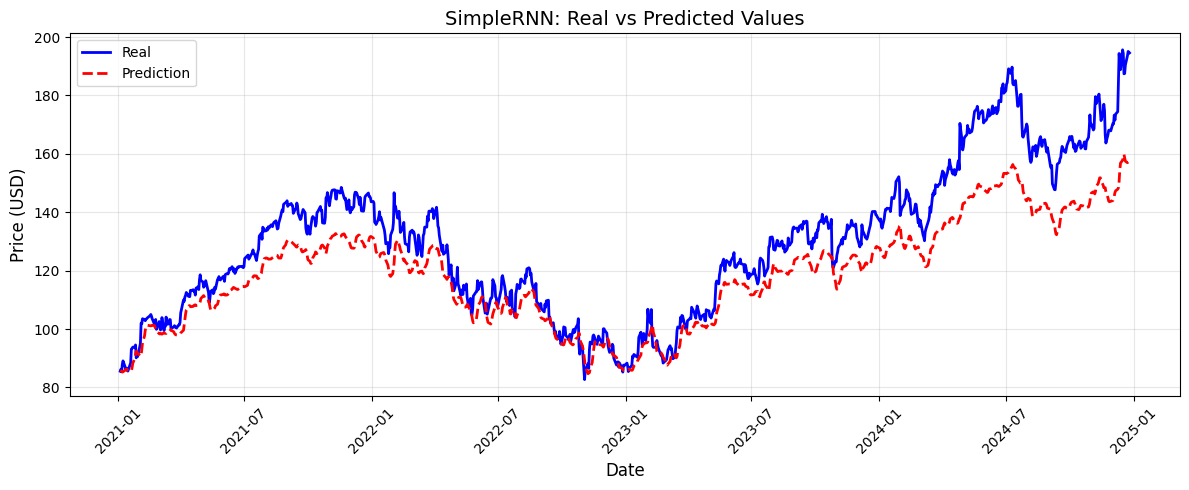

In [29]:
prediction_plot(lstm_pred)

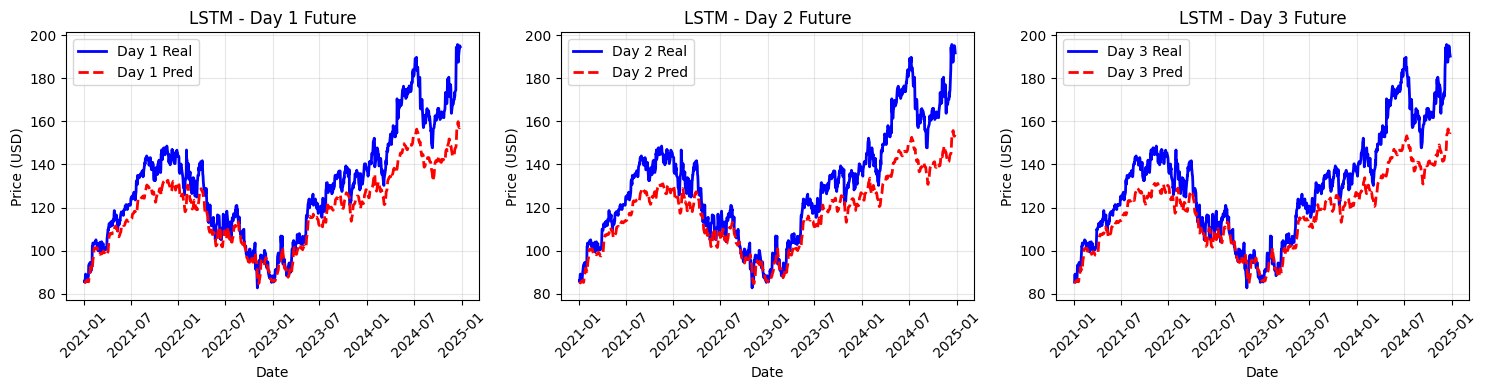

In [30]:
# Plot all 3 future days separately for LSTM
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(y_test[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Real', color='blue', linewidth=2)
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(lstm_pred[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Pred', color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'LSTM - Day {i+1} Future')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## GRU Model

In [32]:
from tensorflow.keras.layers import GRU

In [33]:
gru_model = Sequential([
    GRU(units=50, return_sequences=True, input_shape=(X_steps, 1)),
    Dropout(0.2),
    GRU(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(y_steps)
])


C:\Users\Ayda\tf_env_310\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Model Compile

In [35]:
gru_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 10, 50)              │           7,950 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 10, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_1 (GRU)                          │ (None, 50)                  │          15,300 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             153 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,403 (91.42 KB)

 Trainable params: 23,403 (91.42 KB)

 Non-trainable params: 0 (0.00 B)

## Model fit

In [36]:
gru_history = gru_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0713 - mae: 0.1965 - val_loss: 0.3399 - val_mae: 0.4755
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0163 - mae: 0.1007 - val_loss: 0.3335 - val_mae: 0.4705
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0091 - mae: 0.0707 - val_loss: 0.2089 - val_mae: 0.3659
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0072 - mae: 0.0623 - val_loss: 0.1240 - val_mae: 0.2662
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0068 - mae: 0.0601 - val_loss: 0.0949 - val_mae: 0.2258
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0066 - mae: 0.0595 - val_loss: 0.1262 - val_mae: 0.2755
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0062 - mae: 0.0575 - val_loss: 0.1174 - val_mae: 0.2672
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0060 - mae: 0.0563 - val_loss: 0.1124 - val_mae: 0.2611
Epoch 9/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.005

## Model Evaluation

In [37]:
gru_train_mae = gru_history.history['mae'][-1]
gru_val_mae = gru_history.history['val_mae'][-1]

print(f"\nGRU Results:")
print(f"Train MAE: {gru_train_mae:.5f}")
print(f"Validation MAE: {gru_val_mae:.5f}")


GRU Results:
Train MAE: 0.04591
Validation MAE: 0.13006


## Model Prediction

In [38]:
gru_pred = gru_model.predict(X_test)
print(f"Predictions shape: {gru_pred.shape}")


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Predictions shape: (1002, 3)


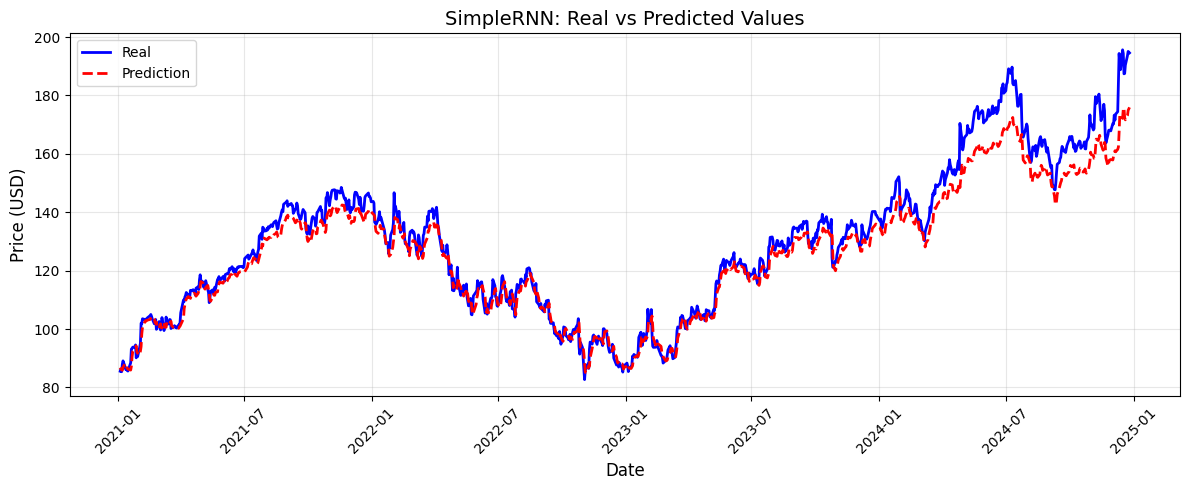

In [39]:
prediction_plot(gru_pred)

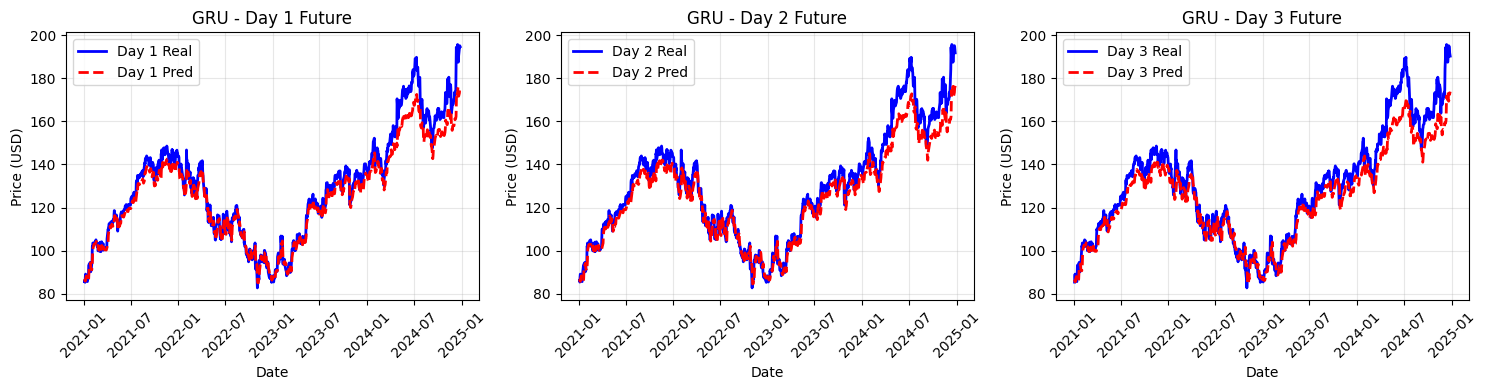

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(y_test[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Real', color='blue', linewidth=2)
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(gru_pred[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Pred', color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'GRU - Day {i+1} Future')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Composition Model lSTM & GRU

In [49]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout

# architecture 1: LSTM → GRU → Dense
model1 = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_steps, 1)),
    Dropout(0.2),
    GRU(64, return_sequences=False),
    Dropout(0.2),
    Dense(y_steps)
])
model1.compile(optimizer='adam', loss='mse', metrics=['mae'])
print("✅ Model 1 (LSTM→GRU) compiled successfully")


# architecture 2: GRU → LSTM → Dense

model2 = Sequential([
    GRU(64, return_sequences=True, input_shape=(X_steps, 1)),
    Dropout(0.2),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(y_steps)
])
model2.compile(optimizer='adam', loss='mse', metrics=['mae'])
print("✅ Model 2 (GRU→LSTM) compiled successfully")


# architecture 3: LSTM → LSTM → GRU → Dense

model3 = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_steps, 1)),
    Dropout(0.2),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    GRU(32, return_sequences=False),
    Dropout(0.2),
    Dense(y_steps)
])
model3.compile(optimizer='adam', loss='mse', metrics=['mae'])
print("✅ Model 3 (LSTM→LSTM→GRU) compiled successfully")

✅ Model 1 (LSTM→GRU) compiled successfully
✅ Model 2 (GRU→LSTM) compiled successfully
✅ Model 3 (LSTM→LSTM→GRU) compiled successfully


## Training and evaluation of all three Models

In [51]:
#  Model 1:
history1 = model1.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=30, batch_size=32, verbose=1)
mae1 = history1.history['val_mae'][-1]
print(f"Model 1 (LSTM→GRU) MAE: {mae1:.5f}")

# Model 2:
history2 = model2.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=30, batch_size=32, verbose=1)
mae2 = history2.history['val_mae'][-1]
print(f"Model 2 (GRU→LSTM) MAE: {mae2:.5f}")

# Model 3:
history3 = model3.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=30, batch_size=32, verbose=1)
mae3 = history3.history['val_mae'][-1]
print(f"Model 3 (LSTM→LSTM→GRU) MAE: {mae3:.5f}")


# Final comparison

print("\n" + "="*50)
print("HYBRID MODELS COMPARISON")
print("="*50)
print(f"LSTM→GRU MAE:       {mae1:.5f}")
print(f"GRU→LSTM MAE:       {mae2:.5f}")
print(f"LSTM→LSTM→GRU MAE:  {mae3:.5f}")

best = min([(mae1, "LSTM→GRU"), (mae2, "GRU→LSTM"), (mae3, "LSTM→LSTM→GRU")])
print(f"\n BEST: {best[1]} with MAE = {best[0]:.5f}")

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0046 - mae: 0.0494 - val_loss: 0.0959 - val_mae: 0.2569
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0044 - mae: 0.0488 - val_loss: 0.0304 - val_mae: 0.1326
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0045 - mae: 0.0486 - val_loss: 0.0462 - val_mae: 0.1694
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0043 - mae: 0.0482 - val_loss: 0.0413 - val_mae: 0.1591
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0041 - mae: 0.0476 - val_loss: 0.0705 - val_mae: 0.2205
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0051 - mae: 0.0523 - val_loss: 0.1289 - val_mae: 0.3129
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0041 - mae: 0.0470 - val_loss: 0.0448 - val_mae: 0.1694
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0046 - mae: 0.0489 - val_loss: 0.0400 - val_mae: 0.1570
Epoch 9/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.005

## Model Evaluation

In [52]:
# Selecting the best model based on MAE
if mae1 < mae2 and mae1 < mae3:
    best_hybrid_model = model1
    best_hybrid_pred = model1.predict(X_test)
    best_hybrid_mae = mae1
    print("✅ Best hybrid model: LSTM→GRU")
elif mae2 < mae1 and mae2 < mae3:
    best_hybrid_model = model2
    best_hybrid_pred = model2.predict(X_test)
    best_hybrid_mae = mae2
    print("✅ Best hybrid model: GRU→LSTM")
else:
    best_hybrid_model = model3
    best_hybrid_pred = model3.predict(X_test)
    best_hybrid_mae = mae3
    print("✅ Best hybrid model: LSTM→LSTM→GRU")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
✅ Best hybrid model: LSTM→GRU


## Prediction

In [54]:
## Best hybrid model (same as LSTM→GRU)
best_hybrid_model = model1   ## Because the best smell
hybrid_pred = best_hybrid_model.predict(X_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


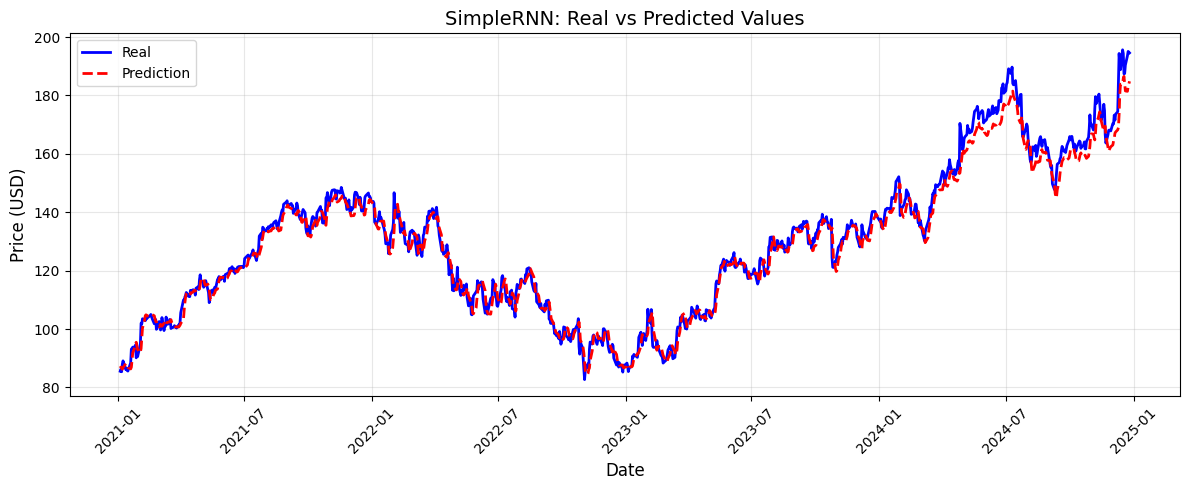

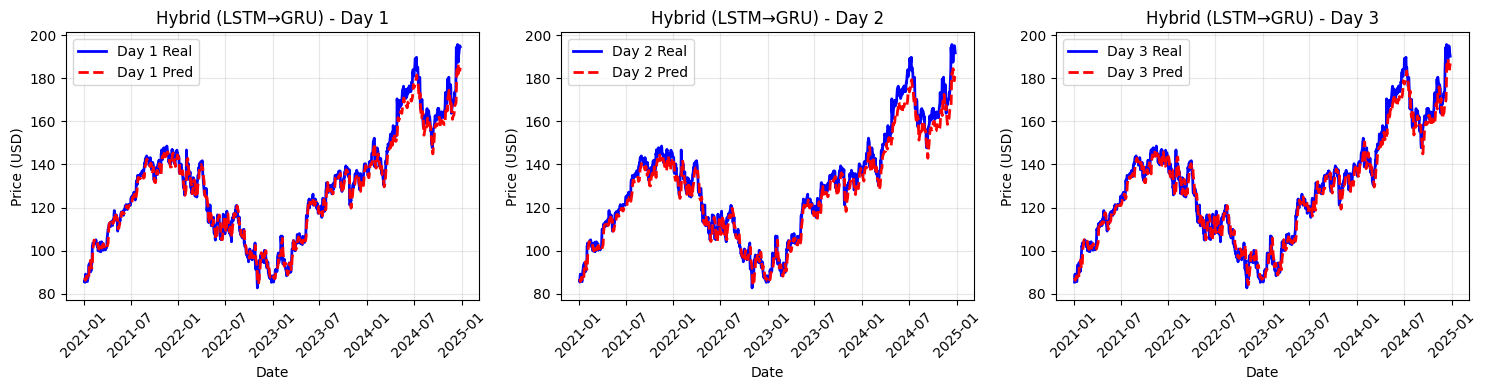

In [55]:
## day 1 :
prediction_plot(hybrid_pred)

#3 separate days
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(y_test[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Real', color='blue', linewidth=2)
    axes[i].plot(df_clean["2021":].index[:len(y_test)],
                 scaler.inverse_transform(hybrid_pred[:, i].reshape(-1, 1)), 
                 label=f'Day {i+1} Pred', color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'Hybrid (LSTM→GRU) - Day {i+1}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Final Result

In [56]:
print("="*60)
print("FINAL MODEL COMPARISON (Validation MAE)")
print("="*60)
print(f"SimpleRNN MAE:           {val_mae:.5f}")
print(f"LSTM MAE:                {lstm_val_mae:.5f}")
print(f"GRU MAE:                 {gru_val_mae:.5f}")
print(f"Hybrid (LSTM→GRU) MAE:   {mae1:.5f}")  # همان 0.17112
print("-"*60)

models = {
    'SimpleRNN': val_mae,
    'LSTM': lstm_val_mae,
    'GRU': gru_val_mae,
    'Hybrid (LSTM→GRU)': mae1
}
best = min(models, key=models.get)
print(f" BEST MODEL: {best} with MAE = {models[best]:.5f}")

FINAL MODEL COMPARISON (Validation MAE)
SimpleRNN MAE:           0.65732
LSTM MAE:                0.29048
GRU MAE:                 0.13006
Hybrid (LSTM→GRU) MAE:   0.08910
------------------------------------------------------------
 BEST MODEL: Hybrid (LSTM→GRU) with MAE = 0.08910


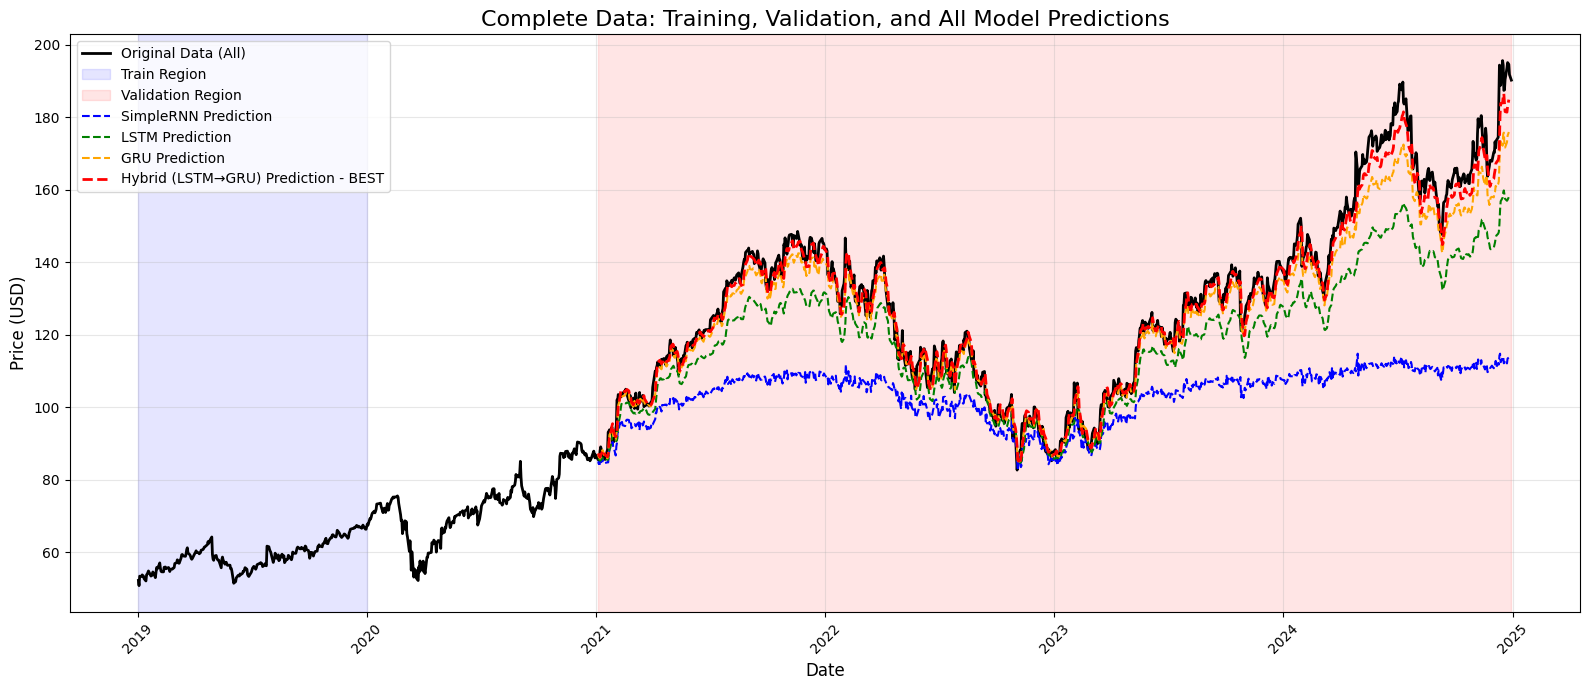

In [58]:
plt.figure(figsize=(16, 7))

# 1. Original data (all data)

plt.plot(df_clean.index, 
         df_clean['Close'].values, 
         label='Original Data (All)', color='black', linewidth=2)


# 2. Train data (specify range)

plt.axvspan(df_clean.index[0], df_clean["2020":].index[0], 
            alpha=0.1, color='blue', label='Train Region')


# 3. Validation/Test data (specify scope)

plt.axvspan(df_clean["2021":].index[0], df_clean.index[-1], 
            alpha=0.1, color='red', label='Validation Region')


# 4. SimpleRNN model prediction (only on Validation)

plt.plot(df_clean["2021":].index[:len(y_test)],
         scaler.inverse_transform(simple_rnn_pred[:, 0].reshape(-1, 1)), 
         label='SimpleRNN Prediction', color='blue', linestyle='--', linewidth=1.5)


# 5. LSTM model prediction

plt.plot(df_clean["2021":].index[:len(y_test)],
         scaler.inverse_transform(lstm_pred[:, 0].reshape(-1, 1)), 
         label='LSTM Prediction', color='green', linestyle='--', linewidth=1.5)


# 6. GRU model prediction

plt.plot(df_clean["2021":].index[:len(y_test)],
         scaler.inverse_transform(gru_pred[:, 0].reshape(-1, 1)), 
         label='GRU Prediction', color='orange', linestyle='--', linewidth=1.5)


# 7. Hybrid model prediction (LSTM→GRU)

plt.plot(df_clean["2021":].index[:len(y_test)],
         scaler.inverse_transform(hybrid_pred[:, 0].reshape(-1, 1)), 
         label='Hybrid (LSTM→GRU) Prediction - BEST', color='red', linestyle='--', linewidth=2)


# Chart settings

plt.title('Complete Data: Training, Validation, and All Model Predictions', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()